<a href="https://colab.research.google.com/github/ma-hi-ka/dc-email-extraction/blob/main/Scoring_Metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
#Mount and connect your Google Drive for data access
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [10]:
#Connect to the SQLite database containing raw investor updates
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

#Path to the cleaned database from Notebook 1
UPDATED_DB = "/content/drive/MyDrive/updated_investor_updates.db"
conn = sqlite3.connect(UPDATED_DB)
df = pd.read_sql_query("SELECT * FROM investor_updates", conn)
conn.close()

#Load the founder dataset. Download the founder_data google sheet as a .xlsx file, update it in your Drive, then run the code
founder_df = pd.read_excel('/content/drive/MyDrive/founder_data.xlsx') #adjust the pathname as per where it is saved in your drive

# Ensure the update_date is formatted as datetime.date (not timestamp)
df['update_date'] = pd.to_datetime(df['update_date']).dt.date

### SCORING METRICS

In [11]:
import pandas as pd
from datetime import datetime
import numpy as np

#Compute the company's age in months relative to today's date
founder_df['company_age'] = pd.to_datetime(founder_df['company_age'])
today = pd.to_datetime(datetime.today())
founder_df['company_age_months'] = ((today - founder_df['company_age']) / pd.Timedelta(days=30)).astype(int)

age_lookup = (
    founder_df
      .drop_duplicates(subset='company_name')
      .loc[:, ['company_name','company_age_months']]
)

df = df.merge(age_lookup, on='company_name', how='left')

#DEFINE YOUR KEY SCORING METRICS HERE:

def scoring(row):
    age = row['company_age_months']
    m = {}

#To add/remove any scoring metrics, do so here:

    #Metric 1: Positive Cashflow
    #Has the same computation regardless of company age hence separated up here.
    if pd.notnull(row.get('expenses')):
        m['positive_cashflow'] = row['arr'] > row['expenses']
    elif pd.notnull(row.get('burn_rate')):
        m['positive_cashflow'] = row['burn_rate'] < 0
    else:
        m['positive_cashflow'] = False

    #Age specific metrics computation
    #Scoring metrics for companies less then 6 months old
    if age < 6:
        m['high_growth'] = row['yoy_revenue_growth'] > 0.10     #Metric 2: High Growth
        m['strong_cash'] = row['runway'] > 30                   #Metric 3: Strong Cash
        m['decent_arr'] = row['arr'] > 500_000                  #Metric 4: Decent Arr
        m['user_base']  = row['active_customers'] > 10          #Metric 5: User Base

    #Scoring metrics for companies of age 6 months upto 12 months old.
    elif 6 <= age < 12:
        m['high_growth'] = (row['yoy_revenue_growth'] > 0.10) & (row['yoy_revenue_growth'] < 0.25)       #Metric 2: High Growth
        m['strong_cash'] = (row['runway'] > 12) & (row['runway'] < 30)                                   #Metric 3: Strong Cash
        m['decent_arr'] = (row['arr'] > 500_000) & (row['arr'] < 750_000)                                #Metric 4: Decent Arr
        m['user_base']  = row['active_customers'] > 25                                                   #Metric 5: User Base

    #Scoring metrics for companies more than 12 months old (More Mature)
    else:
        m['high_growth'] = row['yoy_revenue_growth'] > 0.25     #Metric 2: High Growth
        m['strong_cash'] = row['runway'] > 12                   #Metric 3: Strong Cash
        m['decent_arr'] = row['arr'] > 750_000                  #Metric 4: Decent Arr
        m['user_base']  = row['active_customers'] > 50          #Metric 5: User Base


    #The score calculated is the sum of all the 'True' values a company gets flagged for by the above metrics.
    score = sum(int(flag) for flag in m.values())
    m['score'] = score
    return pd.Series(m)

scored = df.apply(scoring, axis=1)
df = pd.concat([df, scored], axis=1)

#Segregation of company quartile ranking based on their score
df['quartile'] = pd.cut(
    df['score'],
    bins=[-1, 1, 3, 5],     #Lower bin value = minimum value for the range - 1. Upper bin value = maximum value of the range.
    labels=['Bottom (Score < 2)','Middle (Score: 2–3)','Upper (Score >= 4)'])


# Challenge: All the companies have an inconsistent format for sending their updates. As such, there are some metrics that are missing, that we can't extrapolate or replace values with.
# So when computing the company's score, the absence of values present, i.e. NA, are counted as a False. This affects the score of the company, and can tamper with the effectiveness of the scoring system.

# Solution: Creating a new column depicted the number of NA values present in the columns utilised for score calculation for each company. This increases transparency and allows us to make
# more informed decisions when comparing the scores obtained by each company.

# Saving all the columns that are directly used for score computation
scoring_columns = [
    'yoy_revenue_growth',
    'runway',
    'arr',
    'active_customers',
    'expenses',
    'burn_rate'
]
# Count the number of NAs
df['missing_metrics_count'] = df[scoring_columns].isna().sum(axis=1)
#Display the columns
from IPython.display import display
df_sorted = df.sort_values(by=["score", "company_name", "update_date", "missing_metrics_count"], ascending=[False, False, True, True])   #Display companies from highest scores to lowest scores.
df_sorted = df_sorted.reset_index(drop=True)

#Add/remove column names from here, to control which columns are displayed in the output table.
display(df_sorted[['company_name', 'update_date', 'quartile', 'score', 'arr', 'expenses', 'yoy_revenue_growth', 'runway', 'active_customers', 'burn_rate',
                   'positive_cashflow',	'high_growth','strong_cash','decent_arr',	'user_base', 'missing_metrics_count']])


,company_name,update_date,quartile,score,arr,expenses,yoy_revenue_growth,runway,active_customers,burn_rate,positive_cashflow,high_growth,strong_cash,decent_arr,user_base,missing_metrics_count
0,Omnistrate,2024-12-31,Upper (Score >= 4),4,1250000.0,NaN,50.0,15.625000,100.0,160000.0,False,True,True,True,True,1
1,Liquid Instruments,2025-05-02,Upper (Score >= 4),4,22932000.0,19498000.0,22.0,22.250000,NaN,800000.0,True,True,True,True,False,1
2,Cleva,2025-01-16,Upper (Score >= 4),4,4524000.0,414000.0,4400.0,NaN,320000.0,NaN,True,True,False,True,True,2
3,Liquid Instruments,2024-07-12,Middle (Score: 2–3),3,18972000.0,3580000.0,55.0,1.350313,NaN,6400000.0,True,True,False,True,False,1
4,HockeyStack,2025-01-02,Middle (Score: 2–3),3,4480000.0,NaN,400.0,NaN,139.0,455000.0,False,True,False,True,True,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,Hegel AI Inc,2025-02-20,Bottom (Score < 2),0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,6
67,Hegel AI,2025-06-04,Bottom (Score < 2),0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,6
68,Corgea,2024-10-02,Bottom (Score < 2),0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,6
69,Corgea,2025-03-29,Bottom (Score < 2),0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,6


# Plotting the scores for each company

In [12]:
#Creating a scatter plot to display the scores of each company update

import plotly.graph_objects as go
import plotly.express as px
import numpy as np
import pandas as pd

colors = ['#A30000', '#CD5334', '#E28413', '#6CAE75', '#3A5A40', '#005E7C', '#6D72C3', '#443850', '#2D3047', '#8E5572', '#85C1E9', '#8F754F', '#808080']

df_sorted = df.sort_values(by=['company_name', 'update_date']).reset_index(drop=True)
company_names = df_sorted['company_name'].unique()
company_to_x = {name: i for i, name in enumerate(company_names)}
df_sorted['x'] = df_sorted['company_name'].map(company_to_x)

# Ensuring that the points don't overlap each other, and are displayed next to each other.
def calculate_even_jitter(group_df):
    n = len(group_df)
    if n == 1:
        return [0]
    width = 0.12
    positions = np.linspace(-width, width, n)
    return positions

df_sorted['jitter'] = df_sorted.groupby('company_name', group_keys=False).apply(
    lambda x: pd.Series(calculate_even_jitter(x), index=x.index)
)

def calculate_sorted_even_jitter(group_df):
    n = len(group_df)
    if n == 1:
        return [0]

    sorted_indices = group_df['score'].argsort()

    width = 0.15
    positions = np.linspace(-width, width, n)

    jitter_values = np.zeros(n)
    jitter_values[sorted_indices] = positions

    return jitter_values


df_sorted['x_jittered'] = df_sorted['x'] + df_sorted['jitter']

company_colors = {name: colors[i % len(colors)] for i, name in enumerate(company_names)}
df_sorted['color'] = df_sorted['company_name'].map(company_colors)

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=df_sorted['x_jittered'],
    y=df_sorted['score'],
    mode='markers',
    marker=dict(
        size=10,
        color=df_sorted['color'],
        line=dict(width=1.5, color='white'),
        opacity=0.8
    ),
    hovertemplate='<b>%{customdata[0]}</b><br>' +
                  'Date: %{customdata[1]}<br>' +
                  'Score: %{y:.2f}<br>' +
                  '<extra></extra>',
    customdata=np.column_stack((df_sorted['company_name'], df_sorted['update_date'])),
    showlegend=False
))

fig.update_layout(
    title=dict(
        text='Company Performance Analytics',
        x=0.5,
        font=dict(size=24, color='#2c3e50', family='Arial, sans-serif'),
        pad=dict(t=30)
    ),
    xaxis=dict(
        title=dict(text='Company', font=dict(size=16, color='#34495e')),
        tickvals=list(range(len(company_names))),
        ticktext=company_names,
        tickangle=45,
        tickfont=dict(size=12, color='#34495e'),
        gridcolor='rgba(189, 195, 199, 0.2)',
        gridwidth=0.8,
        showline=True,
        linecolor='#bdc3c7',
        linewidth=1,
        showgrid=False
    ),
    yaxis=dict(
        title=dict(text='Performance Score', font=dict(size=16, color='#34495e')),
        tickfont=dict(size=11, color='#34495e'),
        gridcolor='rgba(189, 195, 199, 0.2)',
        gridwidth=0.8,
        showline=True,
        linecolor='#bdc3c7',
        linewidth=1
    ),
    plot_bgcolor='#fdfdfd',
    paper_bgcolor='white',
    width=1000,
    height=600,
    margin=dict(l=80, r=50, t=100, b=120),
    hoverlabel=dict(
        bgcolor='white',
        bordercolor='black',
        font=dict(size=12, color='#2c3e50')
    ))

for i in range(len(company_names)):
    fig.add_vline(
        x=i,
        line_color='rgba(189, 195, 199, 0.2)',
        line_width=0.8)

quartiles = np.percentile(df_sorted['score'], [25, 50, 75])
for i, q in enumerate(quartiles):
    alpha = 0.1 if i != 1 else 0.15
    fig.add_hline(
        y=q,
        line_dash="dash",
        line_color='#34495e',
        opacity=alpha,
        line_width=1)

fig.update_xaxes(showline=True, linewidth=1, linecolor='#bdc3c7', mirror=False)
fig.update_yaxes(showline=True, linewidth=1, linecolor='#bdc3c7', mirror=False)

fig.show()

# Additional Method 3: Bee swarm style jitter (most advanced) --> to fix issue of misaligned datapoints
def beeswarm_jitter(group_df, y_col='score'):
    n = len(group_df)
    if n == 1:
        return [0]

    y_values = group_df[y_col].values
    positions = np.zeros(n)

    sorted_indices = np.argsort(y_values)
    positions[sorted_indices[0]] = 0

    for i in range(1, n):
        current_idx = sorted_indices[i]
        current_y = y_values[current_idx]

        min_distance = 0.02
        best_pos = 0

        for offset in np.arange(0, 0.15, 0.01):
            for direction in [1, -1]:
                test_pos = direction * offset

                conflict = False
                for j in range(i):
                    prev_idx = sorted_indices[j]
                    prev_y = y_values[prev_idx]
                    prev_pos = positions[prev_idx]

                    h_dist = abs(test_pos - prev_pos)
                    v_dist = abs(current_y - prev_y)

                    if h_dist < min_distance and v_dist < 0.1:
                        conflict = True
                        break

                if not conflict:
                    best_pos = test_pos
                    break

            if not conflict:
                break

        positions[current_idx] = best_pos

    return positions


/tmp/ipython-input-12-837714542.py:24: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



**But, this is not indicative of whether the company has performed better or worse over time. So, let's calculate the difference in scores and see if they have improved or not. If they have improved this period compared to the last update, an upwards green arrow will be shown. If there is a disimprovement, a downwards red arrow will be shown.**

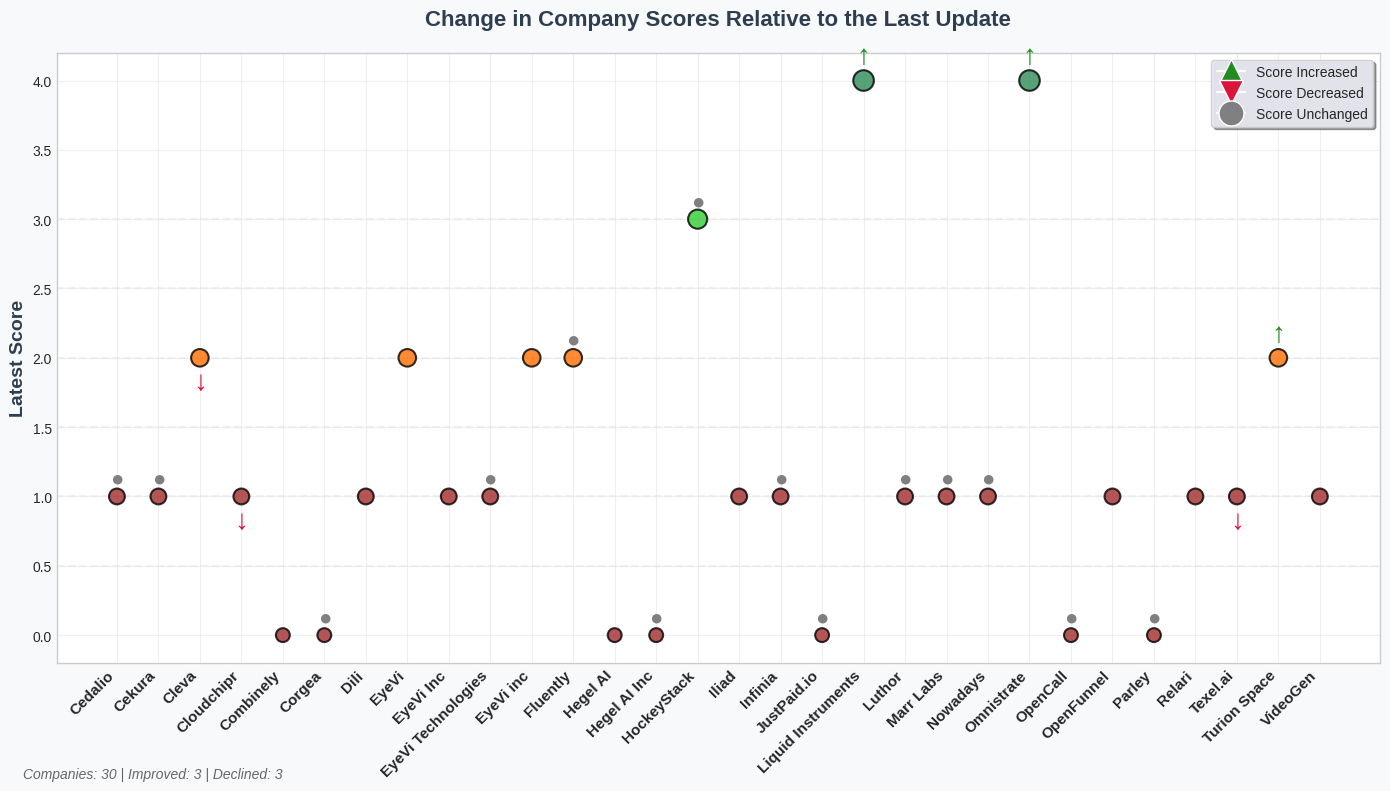

In [13]:
#Plotting a graph that shows if the company has had an improvemnt, disimprovement or no change since the last update.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = df.sort_values(['company_name', 'update_date'])
df['score_diff'] = df.groupby('company_name')['score'].diff()
#Comparing the latest update to the second-last update
latest_two = df.groupby('company_name').tail(2)
latest = latest_two.groupby('company_name').tail(1).copy()

company_names = latest['company_name'].unique()
company_to_x = {name: i for i, name in enumerate(company_names)}
latest['x'] = latest['company_name'].map(company_to_x)

plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor('#f8f9fa')
ax.set_facecolor('#ffffff')

#Setting custom colours for companies with scores within each score range.
def get_score_color(score):
    if score >= 4.0:
        return '#2E8B57'  #Dark Green
    elif score >= 3.0:
        return '#32CD32'  #Green
    elif score >= 2.5:
        return '#ABFF87'  #Light Green
    elif score >= 1.5:
        return '#FF6F00'  #Orange
    else:
        return '#A32C2C'  #Red

scatter_colors = [get_score_color(score) for score in latest['score']]
scatter_sizes = [100 + (score * 30) for score in latest['score']]  # size of the marker is based on score

scatter = ax.scatter(latest['x'], latest['score'],
                    c=scatter_colors, s=scatter_sizes,
                    alpha=0.8, edgecolors='black', linewidth=1.5,
                    zorder=3)

for _, row in latest.iterrows():
    x = row['x']
    y = row['score']
    diff = row['score_diff']

    if pd.notna(diff):
        if diff > 0:
            ax.annotate('↑', (x, y + 0.08), color='#228B22', fontsize=20,
                       ha='center', va='bottom', weight='bold', zorder=4)
        elif diff < 0:
            ax.annotate('↓', (x, y - 0.08), color='#DC143C', fontsize=20,
                       ha='center', va='top', weight='bold', zorder=4)
        else:
            ax.annotate('●', (x, y + 0.05), color='#808080', fontsize=16,
                       ha='center', va='bottom', zorder=4)

score_levels = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
for level in score_levels:
    ax.axhline(y=level, color='#E5E5E5', linestyle='--', alpha=0.5, zorder=1)

ax.set_xticks(np.arange(len(company_names)))
ax.set_xticklabels(company_names, rotation=45, ha='right', fontsize=11, weight='bold')
ax.set_ylabel('Latest Score', fontsize=14, weight='bold', color='#2C3E50')
ax.set_title('Change in Company Scores Relative to the Last Update', fontsize=16, weight='bold', color='#2C3E50', pad=20)

y_min = latest['score'].min() - 0.2
y_max = latest['score'].max() + 0.2
ax.set_ylim(y_min, y_max)

ax.grid(True, alpha=0.3, linestyle='-', color='#CCCCCC')

#Legend
legend_elements = [
    plt.Line2D([0], [0], marker='^', color='w', markerfacecolor='#228B22', markersize=17, label='Score Increased'),
    plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='#DC143C', markersize=17, label='Score Decreased'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#808080', markersize=18, label='Score Unchanged')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True,
          fancybox=True, shadow=True, framealpha=0.9)

for spine in ax.spines.values():
    spine.set_edgecolor('#CCCCCC')
    spine.set_linewidth(1)

plt.tight_layout()

total_companies = len(latest)
improved = len(latest[latest['score_diff'] > 0])
declined = len(latest[latest['score_diff'] < 0])

stats_text = f"Companies: {total_companies} | Improved: {improved} | Declined: {declined}"
plt.figtext(0.02, 0.02, stats_text, fontsize=10, color='#666666',
           style='italic', ha='left')

plt.show()

# Optional: Save the figure
# plt.savefig('company_scores_aesthetic.png', dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')

COMPARING THE SCORES TO THE PREDICTED VALUES

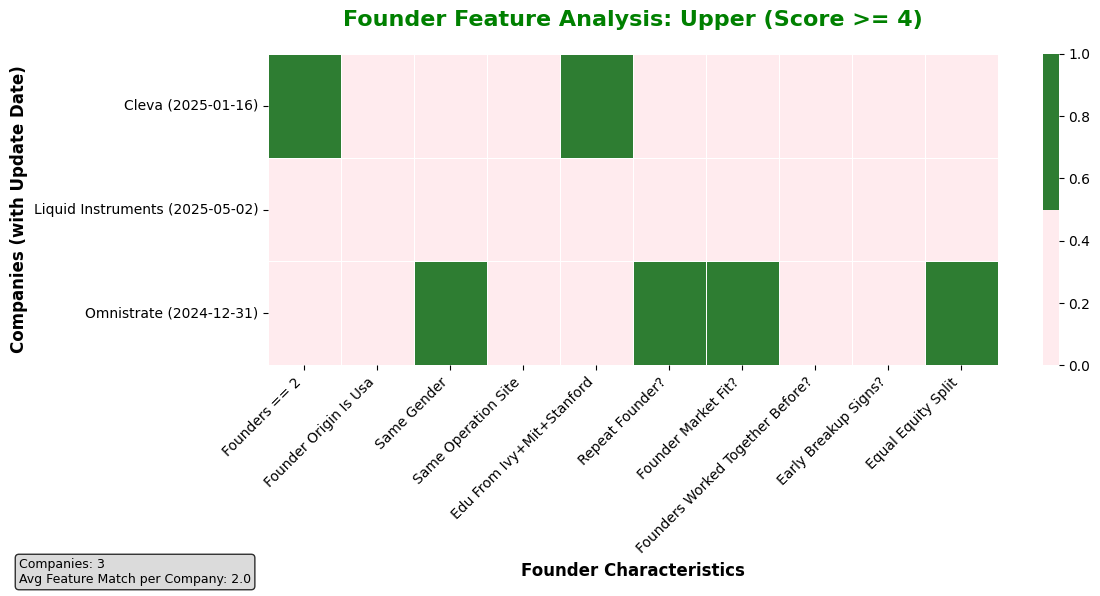

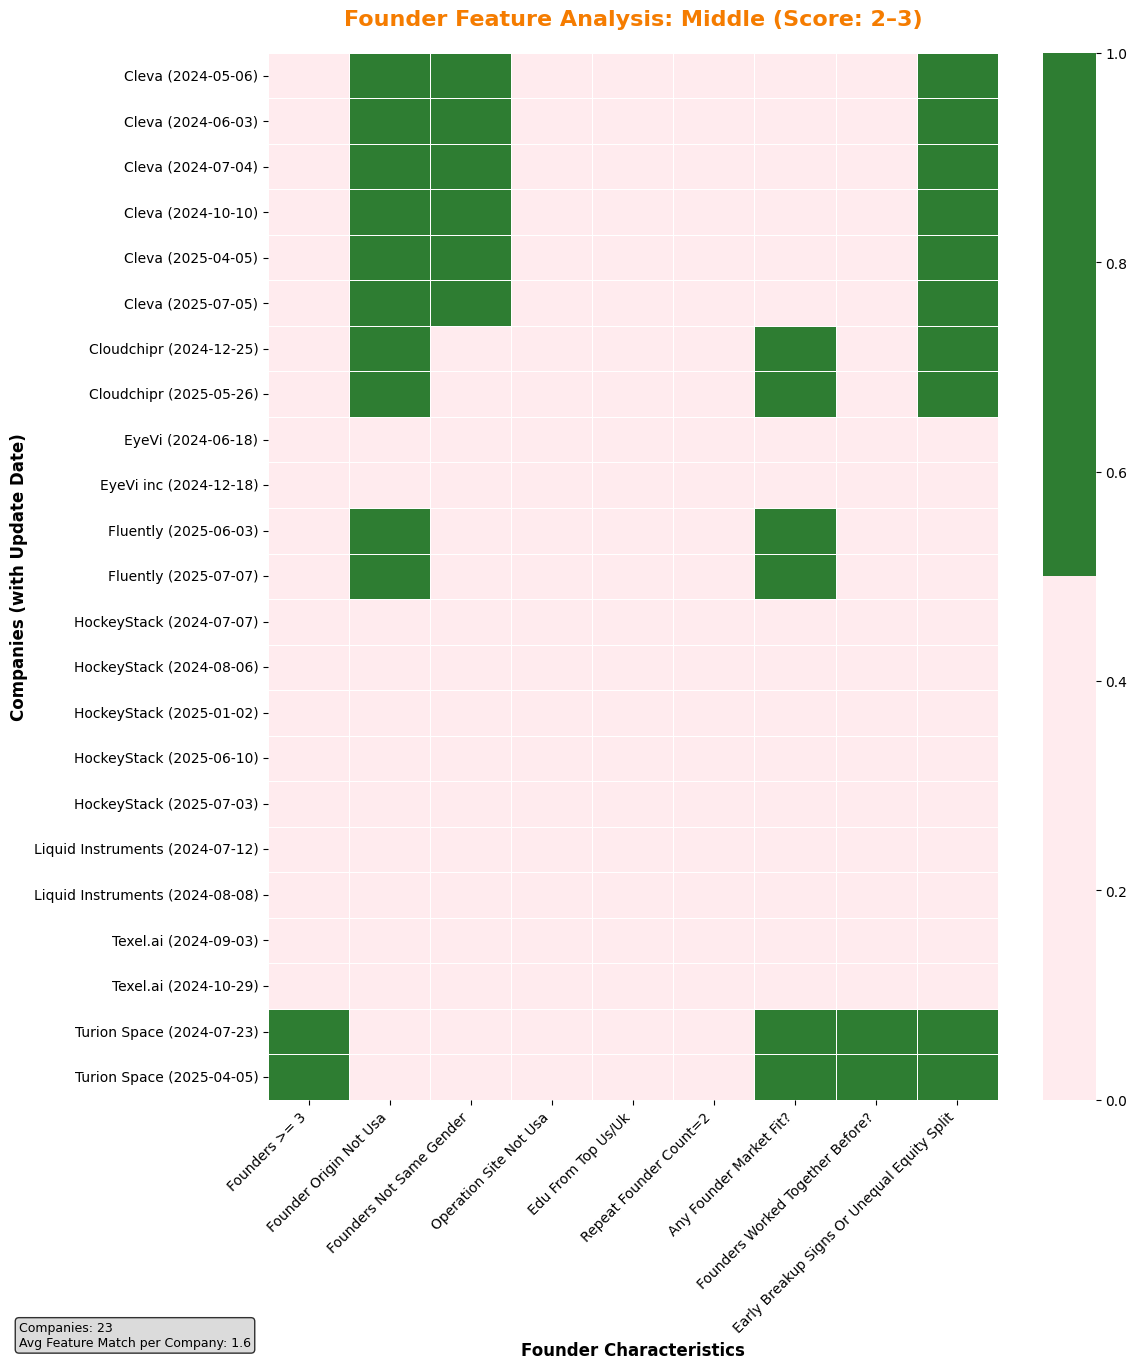

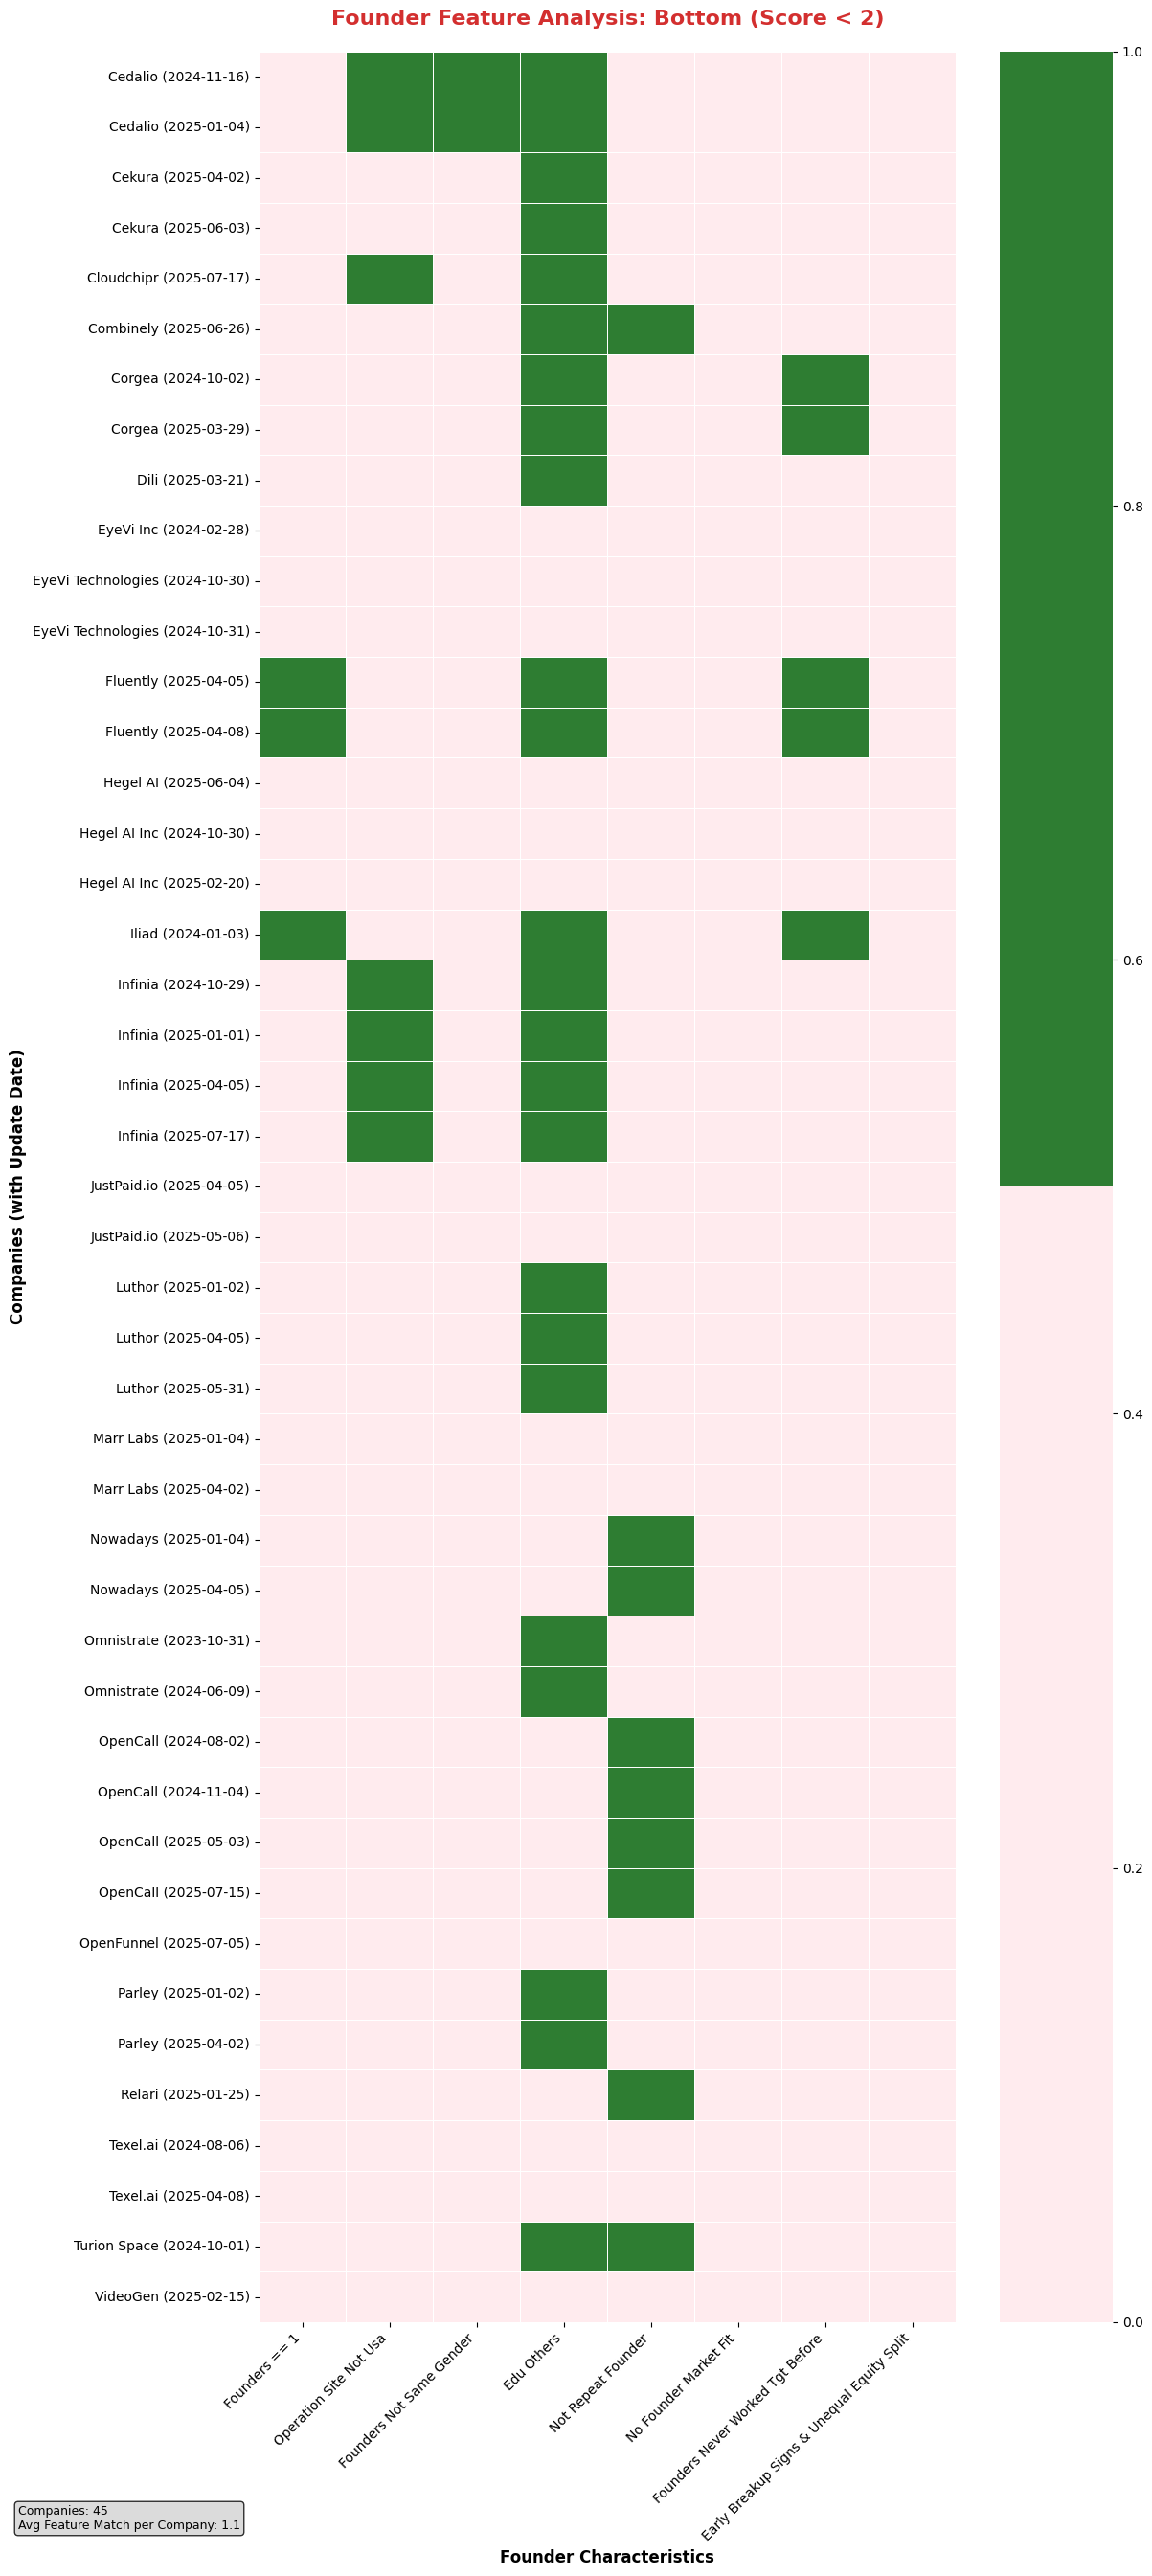

In [14]:
# Comparing the obtained scores with the predicted values for each age group, and determining if the company's performance is influenced by the founder's characteristics
# and if our assumptions about how each metric affects a company's success are accurate.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

binary_cmap = ListedColormap(['#ffebee', '#2e7d32'])

plt.style.use('default')
sns.set_palette("husl")

# List the column names of all the different metrics you are using from the Founder Data sheet below
agg = (
    founder_df
      .groupby('company_name')
      .agg({
          'no_of_founders':                   'first',
          'founder_country_of_origin':        lambda x: [str(c) for c in x if pd.notna(c)],
          'founder_gender':                   lambda x: [str(c) for c in x if pd.notna(c)],
          'founder_operation_site':           lambda x: [str(c) for c in x if pd.notna(c)],
          'founder_education':                lambda x: [str(c) for c in x if pd.notna(c)],
          'repeat_founder':                   lambda x: [str(c) for c in x if pd.notna(c)],
          'founder_market_fit':               lambda x: [str(c) for c in x if pd.notna(c)],
          'duration_cofounders_worked_tgt_b4':lambda x: [str(c) for c in x if pd.notna(c)],
          'early_signs_of_breakup':           lambda x: [str(c) for c in x if pd.notna(c)],
          'equity_split_bw_founders':         lambda x: [str(c) for c in x if pd.notna(c)],
      })
      .reset_index())

full = (
    df[['company_name','quartile','update_date']].merge(agg, on='company_name', how='left')
      .assign(label=lambda d: d['company_name'] + " (" + d['update_date'].astype(str) + ")")
      .set_index('label')
)

# Classifying which universities we are ranking as Top Education, and Middle Education
TOP_EDU = {'harvard','yale','princeton','columbia','cornell','upenn','dartmouth','brown','mit','stanford','berkeley'}
MID_EDU = {'caltech','purdue','northwestern','oxford','cambridge','ucl','imperial','kcl'}

pred_funcs = {
    #PREDICTED VALUES FOR THE UPPER QUARTILE:
    'Upper (Score >= 4)': {
        'founders == 2': lambda r: r['no_of_founders'] == 2,
        'founder_origin_is_USA': lambda r: (
            isinstance(r['founder_country_of_origin'], list)
            and all(c.upper() == 'US' for c in r['founder_country_of_origin'])
        ),
        'same_gender': lambda r: (
            isinstance(r['founder_gender'], list)
            and len(set(r['founder_gender'])) == 1
        ),
        'same_operation_site': lambda r: (
            isinstance(r['founder_operation_site'], list)
            and len(set(r['founder_operation_site'])) == 1
        ),
        'edu_from_Ivy+MIT+Stanford': lambda r: (
            isinstance(r['founder_education'], list)
            and all(
                any(e in edu.lower() for e in TOP_EDU)
                for edu in r['founder_education']
            )
        ),
        'repeat_founder?': lambda r: (
            isinstance(r['repeat_founder'], list)
            and any(x.lower() == 'yes' for x in r['repeat_founder'])
        ),
        'founder_market_fit?': lambda r: (
            isinstance(r['founder_market_fit'], list)
            and any(x.lower() == 'yes' for x in r['founder_market_fit'])
        ),
        'founders_worked_together_before?': lambda r: (
            isinstance(r['duration_cofounders_worked_tgt_b4'], list)
            and any('worked together' in s.lower()
                    for s in r['duration_cofounders_worked_tgt_b4'])
        ),
        'early_breakup_signs?': lambda r: (
            isinstance(r['early_signs_of_breakup'], list)
            and any(x.lower() != 'no' for x in r['early_signs_of_breakup'])
        ),
        'equal_equity_split': lambda r: (
            isinstance(r['equity_split_bw_founders'], list)
            and all(x.lower() == 'equal equity split'
                    for x in r['equity_split_bw_founders'])
        ),
    },
    #PREDICTED VALUES FOR THE MIDDLE QUARTILE:
    'Middle (Score: 2–3)': {
        'founders >= 3': lambda r: r['no_of_founders'] >= 3,
        'founder_origin_not_USA': lambda r: (
            isinstance(r['founder_country_of_origin'], list)
            and any(c.upper() != 'US' for c in r['founder_country_of_origin'])
        ),
        'founders_not_same_gender': lambda r: (
            isinstance(r['founder_gender'], list)
            and len(set(r['founder_gender'])) > 1
        ),
        'operation_site_not_USA': lambda r: (
            isinstance(r['founder_operation_site'], list)
            and all('us' not in s.lower()
                    for s in r['founder_operation_site'])
        ),
        'edu_from_top_US/UK': lambda r: (
            isinstance(r['founder_education'], list)
            and all(
                any(e in edu.lower() for e in MID_EDU)
                for edu in r['founder_education']
            )
        ),
        'repeat_founder_count=2': lambda r: (
            isinstance(r['repeat_founder'], list)
            and sum(x.lower()=='yes' for x in r['repeat_founder']) == 2
        ),
        'any_founder_market_fit?': lambda r: (
            isinstance(r['founder_market_fit'], list)
            and any(x.lower()=='yes' for x in r['founder_market_fit'])
        ),
        'founders_worked_together_before?': lambda r: (
            isinstance(r['duration_cofounders_worked_tgt_b4'], list)
            and any('worked together' in s.lower()
                    for s in r['duration_cofounders_worked_tgt_b4'])
        ),
        'early_breakup_signs_or_unequal_equity_split': lambda r: (
            isinstance(r['early_signs_of_breakup'], list)
            and any(x.lower()!='no'
                    for x in r['early_signs_of_breakup'])
        ) or (
            isinstance(r['equity_split_bw_founders'], list)
            and any('unequal' in x.lower()
                    for x in r['equity_split_bw_founders'])
        ),
    },
    #PREDICTED VALUES FOR THE BOTTOM QUARTILE:
    'Bottom (Score < 2)': {
        'founders == 1': lambda r: r['no_of_founders'] == 1,
        'operation_site_not_USA': lambda r: (
            isinstance(r['founder_operation_site'], list)
            and any('us' not in s.lower()
                    for s in r['founder_operation_site'])
        ),
        'founders_not_same_gender': lambda r: (
            isinstance(r['founder_gender'], list)
            and len(set(r['founder_gender'])) > 1
        ),
        'edu_OTHERS': lambda r: (
            isinstance(r['founder_education'], list)
            and all(
                not any(e in edu.lower() for e in TOP_EDU|MID_EDU)
                for edu in r['founder_education']
            )
        ),
        'not_repeat_founder': lambda r: (
            isinstance(r['repeat_founder'], list)
            and all(x.lower()=='no' for x in r['repeat_founder'])
        ),
        'no_founder_market_fit': lambda r: (
            isinstance(r['founder_market_fit'], list)
            and all(x.lower()=='no' for x in r['founder_market_fit'])
        ),
        'founders_never_worked_tgt_before': lambda r: (
            isinstance(r['duration_cofounders_worked_tgt_b4'], list)
            and all('never' in s.lower()
                    for s in r['duration_cofounders_worked_tgt_b4'])
        ),
        'early_breakup_signs_&_unequal_equity_split': lambda r: (
            isinstance(r['early_signs_of_breakup'], list)
            and any(x.lower()!='no'
                    for x in r['early_signs_of_breakup'])
        ) and (
            isinstance(r['equity_split_bw_founders'], list)
            and any('unequal' in x.lower()
                    for x in r['equity_split_bw_founders'])
        ),
    }
}

# Creating a heatmap to see if the obtained values match our predictions.
# A green box within the heatmap will signify that the company's founder data corroborates our prediction.
def create_enhanced_heatmap(quart, funcs, subset):
    match_df = pd.DataFrame({cond: subset.apply(fn, axis=1) for cond, fn in funcs.items()}).astype(int)

    n_companies = len(match_df)
    n_features = len(match_df.columns)

    fig_width = max(12, n_features * 1.2)
    fig_height = max(6, n_companies * 0.6)

    plt.figure(figsize=(fig_width, fig_height))

    ax = sns.heatmap(
        match_df,
        annot=False,
        cmap=binary_cmap,
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor='white',
        square=False
    )

    quartile_colors = {
        'Upper (Score >= 4)': '#008000',
        'Middle (Score: 2–3)': '#f57c00',
        'Bottom (Score < 2)': '#d32f2f'
    }

    plt.title(
        f"Founder Feature Analysis: {quart}",
        fontsize=16,
        fontweight='bold',
        color=quartile_colors.get(quart, '#333333'),
        pad=20
    )

    plt.xlabel('Founder Characteristics', fontsize=12, fontweight='bold')
    plt.ylabel('Companies (with Update Date)', fontsize=12, fontweight='bold')

    ax.set_xticklabels(
        [label.replace('_', ' ').title() for label in match_df.columns],
        rotation=45,
        ha='right',
        fontsize=10
    )

    ax.set_yticklabels(
        match_df.index,
        rotation=0,
        ha='right',
        fontsize=10
    )

    ax.grid(False)

    match_counts = match_df.sum()
    total_companies = len(match_df)

    summary_text = f"Companies: {total_companies}\nAvg Feature Match per Company: {match_df.sum(axis=1).mean():.1f}"

    plt.figtext(0.02, 0.02, summary_text,
                fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.8))
    plt.tight_layout()
    return plt

for quart, funcs in pred_funcs.items():
    subset = full[full['quartile'] == quart]

    if len(subset) > 0:
        plt = create_enhanced_heatmap(quart, funcs, subset)
        plt.show()
    else:
        print(f"No data available for quartile: {quart}")
